# Corrections made while preparing the ML stage

1. **File name:** the loading cells pointed to `senior_wellness.csv`; the supplied file is `Aging_prediction_dataset.csv`.
2. **Alcohol "missing" values:** the 4,008 blanks were the text `None` (no alcohol), converted to NaN by pandas. They are now kept as a real category (`keep_default_na=False`). The "Unknown" label is no longer needed; the grouping is unchanged, so the statistical results stay the same.
3. **Cell types:** explanation text that was stored in code cells (which breaks *Run All*) was moved to Markdown cells.
4. **Extra checks** for duplicate leakage were added at the end of the notebook.

Re-run the whole notebook (Kernel → Restart & Run All) so every output matches the corrected code.

## 1. Import Required Libraries

Pandas is used for loading, cleaning, manipulating, and analyzing the dataset.

Additional libraries are imported later when required for visualization and statistical analysis.

Pandas is imported as `pd` to perform data manipulation and statistical exploration using DataFrames.

In [1]:
import pandas as pd

## 2. Dataset Loading

The senior wellness dataset is loaded from the project data directory into a Pandas DataFrame.

The DataFrame `df` represents the original dataset before duplicate removal or other cleaning operations.

`pd.read_csv()` reads the CSV file and stores the dataset in the DataFrame `df`.

In [2]:
df = pd.read_csv(
    "../data/Aging_prediction_dataset.csv",
    keep_default_na=False,
    na_values=[""]   # "None" is a real alcohol category, NOT missing
)

## 3. Initial Dataset Inspection

The dataset is inspected to understand its size, structure, column names, data types, and overall organization.

This step helps identify the variables available for subsequent exploratory analysis and machine learning.

`df.shape` returns the number of observations (rows) and variables (columns) in the dataset.

In [3]:
df.shape

(7488, 14)

`df.head()` displays the first five records to provide an initial view of the dataset values and structure.

In [4]:
df.head()

,age,gender,education_years,income_level,physical_activity,smoking_status,chronic_conditions,memory_score,bmi,blood_pressure,diet_quality,alcohol_consumption,social_engagement,aging_outcome
0,53,Male,17,Medium,Low,Former,4,84.158531,20.7,118,Good,Moderate,Moderate,At-risk
1,56,Male,12,Low,Moderate,Never,2,90.078313,25.0,177,Poor,None,Low,At-risk
2,41,Female,15,High,Low,Never,1,96.286948,23.5,177,Good,None,Low,Healthy
3,88,Male,6,Low,Moderate,Never,0,77.222144,27.8,124,Average,Moderate,High,Frail
4,42,Female,13,Medium,High,Never,4,64.413580,26.3,117,Poor,Moderate,Moderate,At-risk


`df.columns` lists all variables present in the dataset.

In [5]:
df.columns

Index(['age', 'gender', 'education_years', 'income_level', 'physical_activity',
       'smoking_status', 'chronic_conditions', 'memory_score', 'bmi',
       'blood_pressure', 'diet_quality', 'alcohol_consumption',
       'social_engagement', 'aging_outcome'],
      dtype='str')

`df.info()` displays the column names, data types, number of non-null observations, and memory usage. It is useful for identifying missing values and checking whether variables have appropriate data types.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7488 entries, 0 to 7487
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  7488 non-null   int64  
 1   gender               7488 non-null   str    
 2   education_years      7488 non-null   int64  
 3   income_level         7488 non-null   str    
 4   physical_activity    7488 non-null   str    
 5   smoking_status       7488 non-null   str    
 6   chronic_conditions   7488 non-null   int64  
 7   memory_score         7488 non-null   float64
 8   bmi                  7488 non-null   float64
 9   blood_pressure       7488 non-null   int64  
 10  diet_quality         7488 non-null   str    
 11  alcohol_consumption  7488 non-null   str    
 12  social_engagement    7488 non-null   str    
 13  aging_outcome        7488 non-null   str    
dtypes: float64(2), int64(4), str(8)
memory usage: 1.1 MB


## 4. Missing Value Analysis

Missing values are examined to determine whether any variables contain incomplete observations.

Identifying missing data is important because machine learning models generally require appropriately handled input values.

This calculates the number of missing values in each column of the original dataset.

In [7]:
df.isnull().sum()

age                    0
gender                 0
education_years        0
income_level           0
physical_activity      0
smoking_status         0
chronic_conditions     0
memory_score           0
bmi                    0
blood_pressure         0
diet_quality           0
alcohol_consumption    0
social_engagement      0
aging_outcome          0
dtype: int64

## 5. Duplicate Record Analysis

Duplicate records are investigated before further analysis because repeated observations can distort descriptive statistics, visualizations, statistical tests, and machine learning evaluation.

The analysis first determines the number and percentage of exact duplicate records.

This counts the number of exact duplicate rows in the dataset.

In [8]:
df.duplicated().sum()

np.int64(5049)

This calculates the number of observations belonging to each `aging_outcome` category in the original dataset.

In [9]:
df["aging_outcome"].value_counts()

aging_outcome
At-risk    2496
Healthy    2496
Frail      2496
Name: count, dtype: int64

The target distribution is converted into percentages to compare the relative proportion of each aging-outcome category.

In [10]:
df["aging_outcome"].value_counts(normalize=True) * 100

aging_outcome
At-risk    33.333333
Healthy    33.333333
Frail      33.333333
Name: proportion, dtype: float64

The percentage of duplicate observations is calculated relative to the total number of records.

A high duplicate percentage indicates that duplicate removal should be considered before machine learning to reduce the possibility of repeated observations affecting model evaluation.

In [11]:
duplicate_percentage = df.duplicated().sum() / len(df) * 100

print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate percentage: 67.43%


## 6. Removing Exact Duplicate Records

Exact duplicate records are removed to create a dataset containing unique observations.

The original and cleaned dataset dimensions are compared to quantify the effect of duplicate removal.

`drop_duplicates()` removes exact duplicate rows.

A separate copy named `df_clean` is created so that subsequent analysis can be performed on the unique observations without modifying the original `df`.

In [12]:
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("After removing duplicates:", df_clean.shape)

Original dataset shape: (7488, 14)
After removing duplicates: (2439, 14)


## 7. Aging Outcome Distribution After Duplicate Removal

The target variable is re-examined after duplicate removal.

This comparison is important because removing duplicate observations changes the distribution of the aging-outcome classes.

The unique dataset has a substantially different target distribution from the original dataset. In particular, the number of Healthy observations becomes very small after duplicate removal.

This class imbalance must be considered during the machine learning stage.

In [13]:
df_clean["aging_outcome"].value_counts()

aging_outcome
Frail      1556
At-risk     861
Healthy      22
Name: count, dtype: int64

In [14]:
df_clean["aging_outcome"].value_counts(normalize=True) * 100

aging_outcome
Frail      63.796638
At-risk    35.301353
Healthy     0.902009
Name: proportion, dtype: float64

## 8. Basic Age Analysis

Age is examined using descriptive statistics and an age threshold to understand the age composition of the dataset.

Descriptive statistics such as count, mean, standard deviation, minimum, quartiles, and maximum are calculated for age.

In [15]:
df_clean["age"].describe()

count    2439.000000
mean       63.806068
std        14.199436
min        40.000000
25%        52.000000
50%        64.000000
75%        75.000000
max        89.000000
Name: age, dtype: float64

The observations are divided into two broad age categories using 60 years as the threshold to understand how many records fall into each group.

In [16]:
print("Age >= 60:", (df_clean["age"] >= 60).sum())
print("Age < 60:", (df_clean["age"] < 60).sum())

Age >= 60: 1446
Age < 60: 993


## 9. Missing Values in the Unique Dataset

Missing values are reassessed after duplicate removal to determine whether any missing-data problems remain in the unique observations.

Alcohol consumption is examined because pandas initially reported 4,008 "missing" values. They are actually the real category `None`.

In [17]:
df_clean.isnull().sum()

age                    0
gender                 0
education_years        0
income_level           0
physical_activity      0
smoking_status         0
chronic_conditions     0
memory_score           0
bmi                    0
blood_pressure         0
diet_quality           0
alcohol_consumption    0
social_engagement      0
aging_outcome          0
dtype: int64

The share of rows with alcohol consumption `None` is calculated. These are valid answers, not missing data.

In [18]:
print(
    "Alcohol rows with the real category 'None' (%):",
    (df_clean["alcohol_consumption"] == "None").mean() * 100
)

Alcohol rows with the real category 'None' (%): 49.48749487494875


## 10. Variable Classification for Exploratory Analysis

The dataset is loaded and variables are divided into categorical and numerical groups.

This classification allows appropriate descriptive statistics, visualizations, and statistical tests to be applied to each type of variable.

The original dataset is loaded again for the subsequent exploratory analysis. This preserves the original dataset structure for the analysis blocks below.

In [19]:
import pandas as pd

df = pd.read_csv(
    "../data/Aging_prediction_dataset.csv",
    keep_default_na=False,
    na_values=[""]   # "None" is a real alcohol category, NOT missing
)

print(df.shape)

(7488, 14)


The categorical variables include demographic, lifestyle, and outcome-related variables such as gender, income level, physical activity, smoking status, diet quality, alcohol consumption, social engagement, and aging outcome.

The frequency of each category is calculated to understand the distribution of categorical variables.

## Categorical Variable Distribution

This section examines the distribution of the categorical variables in the cleaned dataset.

Frequency counts are calculated for each category to understand the composition of the dataset. The analysis includes demographic, lifestyle, and aging-outcome variables.

The cleaned dataset (`df_clean`) is used so that the analysis is based on the 2,439 unique observations after duplicate removal.

In [20]:
categorical_columns = [
    "gender",
    "income_level",
    "physical_activity",
    "smoking_status",
    "diet_quality",
    "alcohol_consumption",
    "social_engagement",
    "aging_outcome"
]

for col in categorical_columns:
    print("\n" + "=" * 50)
    print(col)
    print("=" * 50)
    print(df_clean[col].value_counts(dropna=False))


gender
gender
Male      1225
Female    1214
Name: count, dtype: int64

income_level
income_level
Medium    1179
Low        758
High       502
Name: count, dtype: int64

physical_activity
physical_activity
Moderate    955
Low         948
High        536
Name: count, dtype: int64

smoking_status
smoking_status
Never      1271
Former      695
Current     473
Name: count, dtype: int64

diet_quality
diet_quality
Average    1171
Good        786
Poor        482
Name: count, dtype: int64

alcohol_consumption
alcohol_consumption
None        1207
Moderate     999
Heavy        233
Name: count, dtype: int64

social_engagement
social_engagement
Moderate    1196
Low          727
High         516
Name: count, dtype: int64

aging_outcome
aging_outcome
Frail      1556
At-risk     861
Healthy      22
Name: count, dtype: int64


The numerical variables include age, education years, number of chronic conditions, memory score, BMI, and blood pressure.

Descriptive statistics are calculated to summarize their distributions.

In [21]:
numerical_columns = [
    "age",
    "education_years",
    "chronic_conditions",
    "memory_score",
    "bmi",
    "blood_pressure"
]

df_clean[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
age,2439.0,63.806068,14.199436,40.000000,52.000000,64.000000,75.000000,89.0
education_years,2439.0,10.307913,6.022100,0.000000,5.000000,11.000000,16.000000,20.0
chronic_conditions,2439.0,2.005330,1.426764,0.000000,1.000000,2.000000,3.000000,8.0
memory_score,2439.0,75.217310,9.970597,40.584208,68.226934,75.476072,82.028197,100.0
bmi,2439.0,24.882780,3.957027,9.100000,22.100000,24.900000,27.500000,38.5
blood_pressure,2439.0,138.988930,22.991569,100.000000,120.000000,138.000000,158.000000,179.0


## 11. Alcohol Consumption: "None" Is a Category, Not Missing Data

**Correction:** the 4,008 "missing" values were the text `None` (no alcohol), which pandas converts to NaN by default. The CSV is now read with `keep_default_na=False`, so `None` stays a valid category and no `"Unknown"` label is needed.

Only the `age_group` analysis column is added below.

In [22]:
# Create the cleaned dataset by removing exact duplicate records
df_clean = df.drop_duplicates().copy()

# NOTE: alcohol_consumption keeps its real "None" category (no imputation needed)
# Create age groups for analysis
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[39, 49, 59, 69, 79, 89],
    labels=["40-49", "50-59", "60-69", "70-79", "80-89"]
)

# Check the cleaned dataset
print("Shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nAlcohol categories:")
print(df_clean["alcohol_consumption"].value_counts())

print("\nTarget distribution:")
print(df_clean["aging_outcome"].value_counts())

Shape: (2439, 15)

Missing values:
age                    0
gender                 0
education_years        0
income_level           0
physical_activity      0
smoking_status         0
chronic_conditions     0
memory_score           0
bmi                    0
blood_pressure         0
diet_quality           0
alcohol_consumption    0
social_engagement      0
aging_outcome          0
age_group              0
dtype: int64

Alcohol categories:
alcohol_consumption
None        1207
Moderate     999
Heavy        233
Name: count, dtype: int64

Target distribution:
aging_outcome
Frail      1556
At-risk     861
Healthy      22
Name: count, dtype: int64


## 12. Exploratory Data Visualization

Visualizations are used to understand the distributions of important demographic, lifestyle, and health variables and to examine their relationship with the aging outcome.

### Aging Outcome Distribution

The first visualization shows the number of observations in each aging-outcome category.

A count plot is used to visualize the frequency of At-risk, Frail, and Healthy observations.

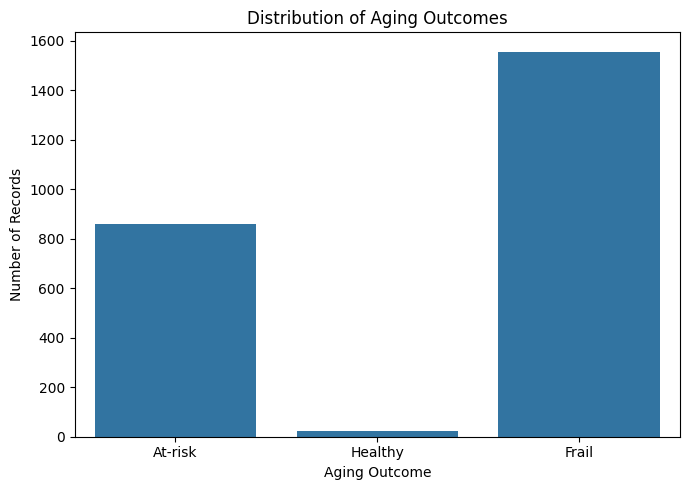

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="aging_outcome"
)

plt.title("Distribution of Aging Outcomes")
plt.xlabel("Aging Outcome")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Age Distribution

The distribution of age is visualized using a histogram with a kernel density estimate to understand the overall age pattern of the observations.

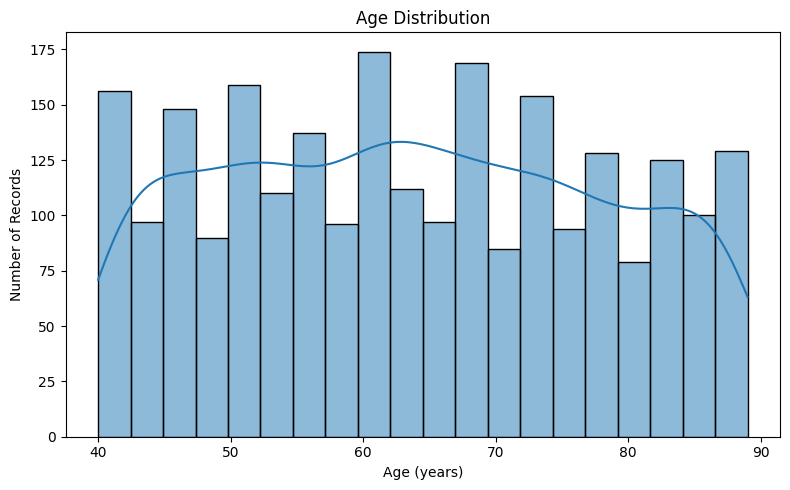

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="age",
    bins=20,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Gender Distribution

A count plot is used to examine the distribution of gender categories in the dataset.

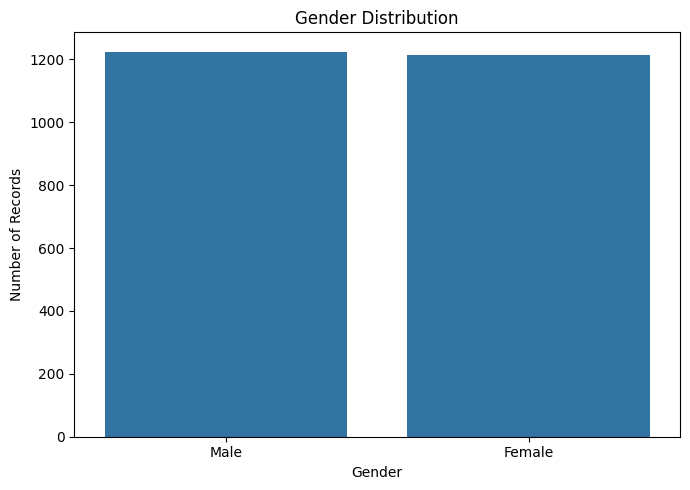

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="gender"
)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Physical Activity and Aging Outcome

Physical activity levels are compared across aging-outcome categories to explore whether different activity levels are associated with different outcome distributions.

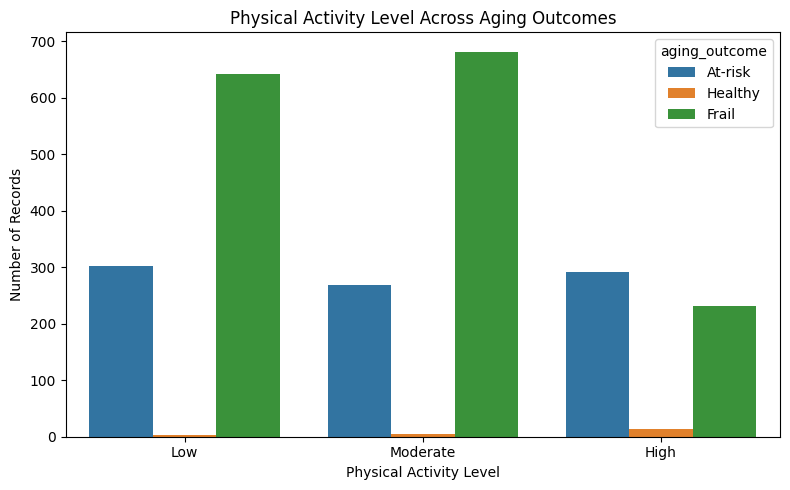

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="physical_activity",
    hue="aging_outcome"
)

plt.title("Physical Activity Level Across Aging Outcomes")
plt.xlabel("Physical Activity Level")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

## 13. BMI Analysis

BMI is examined using both a distribution plot and outcome-based boxplots.

The histogram describes the overall BMI distribution, while the boxplot allows comparison of BMI across the three aging-outcome categories.

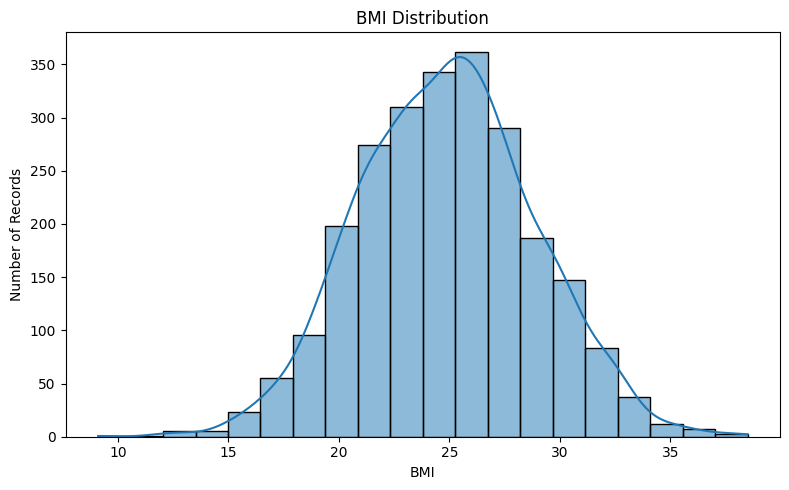

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="bmi",
    bins=20,
    kde=True
)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

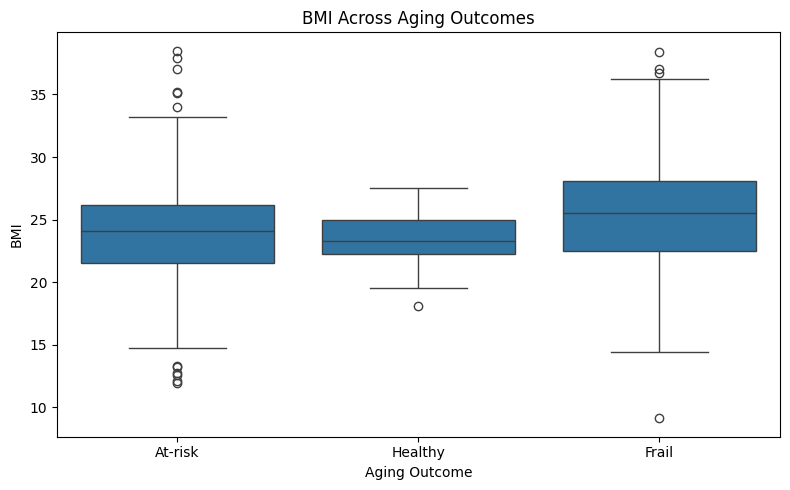

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="aging_outcome",
    y="bmi"
)

plt.title("BMI Across Aging Outcomes")
plt.xlabel("Aging Outcome")
plt.ylabel("BMI")

plt.tight_layout()
plt.show()

## 14. Memory Score Across Aging Outcomes

Memory score is compared across the three aging-outcome categories using boxplots.

This visualization helps identify differences in the central tendency and spread of memory scores between outcome groups.

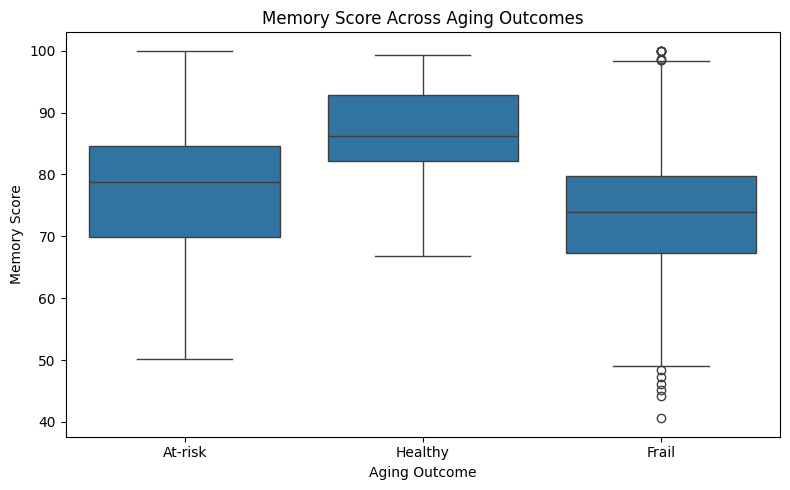

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="aging_outcome",
    y="memory_score"
)

plt.title("Memory Score Across Aging Outcomes")
plt.xlabel("Aging Outcome")
plt.ylabel("Memory Score")

plt.tight_layout()
plt.show()

## 15. Blood Pressure Across Aging Outcomes

Blood pressure is visualized across aging-outcome groups to examine whether noticeable differences exist between the groups.

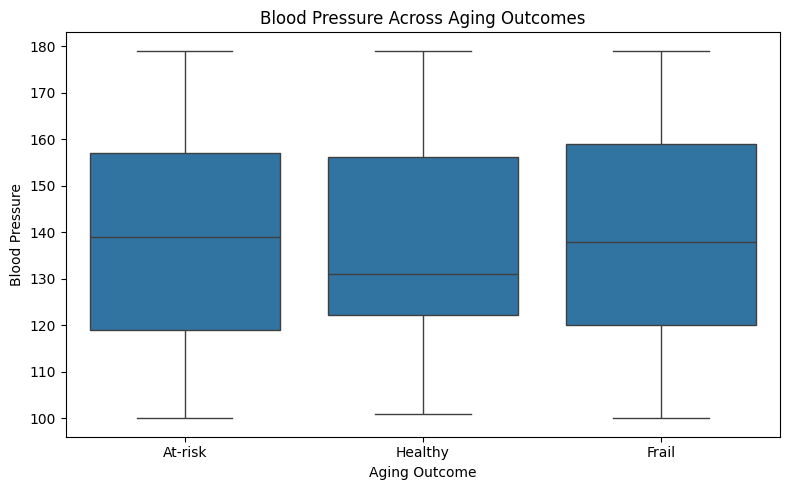

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="aging_outcome",
    y="blood_pressure"
)

plt.title("Blood Pressure Across Aging Outcomes")
plt.xlabel("Aging Outcome")
plt.ylabel("Blood Pressure")

plt.tight_layout()
plt.show()

## 16. Chronic Conditions Across Aging Outcomes

The number of chronic conditions is compared across the aging-outcome categories.

This provides an initial visual assessment of whether the number of chronic conditions differs between groups.

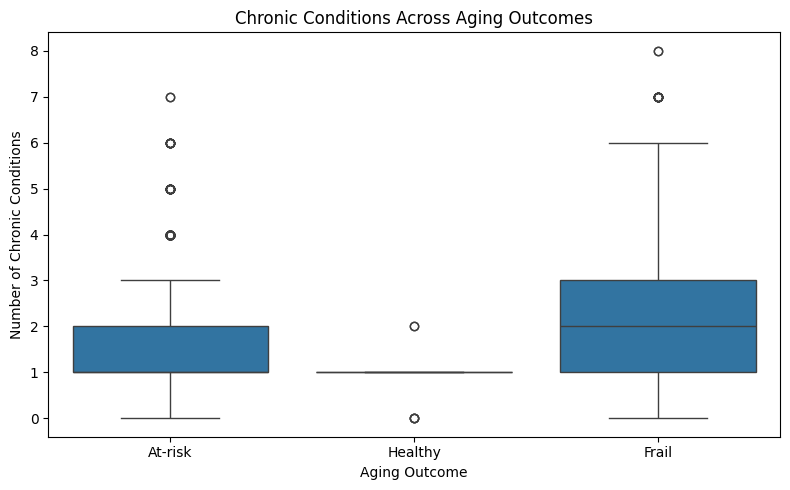

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="aging_outcome",
    y="chronic_conditions"
)

plt.title("Chronic Conditions Across Aging Outcomes")
plt.xlabel("Aging Outcome")
plt.ylabel("Number of Chronic Conditions")

plt.tight_layout()
plt.show()

## 17. Numerical Variable Outlier Analysis

Potential outliers are identified using the Interquartile Range (IQR) method.

For each numerical variable:
- Q1 represents the 25th percentile.
- Q3 represents the 75th percentile.
- IQR is calculated as Q3 − Q1.
- Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

The analysis reports both the number and percentage of potential outliers.

In [32]:
numerical_columns = [
    "age",
    "education_years",
    "chronic_conditions",
    "memory_score",
    "bmi",
    "blood_pressure"
]

outlier_results = []

for col in numerical_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_count = len(outliers)
    outlier_percentage = (outlier_count / len(df_clean)) * 100

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier %": outlier_percentage
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df.round(2)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,age,52.00,75.00,23.0,17.50,109.50,0,0.00
1,education_years,5.00,16.00,11.0,-11.50,32.50,0,0.00
2,chronic_conditions,1.00,3.00,2.0,-2.00,6.00,17,0.70
3,memory_score,68.23,82.03,13.8,47.53,102.73,5,0.21
4,bmi,22.10,27.50,5.4,14.00,35.60,17,0.70
5,blood_pressure,120.00,158.00,38.0,63.00,215.00,0,0.00


## 18. Detailed Examination of Chronic Conditions

The frequency of each number of chronic conditions is examined to understand how the variable is distributed in the dataset.

In [33]:
print("Chronic conditions:")
print(df_clean["chronic_conditions"].value_counts().sort_index())

Chronic conditions:
chronic_conditions
0    317
1    684
2    661
3    423
4    219
5     89
6     29
7     15
8      2
Name: count, dtype: int64


## 19. Examination of Extreme BMI Values

The lowest and highest BMI observations are inspected to determine whether extreme values are present and whether they require further investigation.

In [34]:
print("\nLowest BMI values:")
print(df_clean["bmi"].sort_values().head(20))


Lowest BMI values:
4846     9.1
1438    11.9
3863    12.1
1312    12.6
811     12.7
1198    13.2
1033    13.3
4561    14.4
519     14.5
4748    14.7
747     14.8
55      14.8
1100    15.0
4655    15.0
4196    15.1
1086    15.3
367     15.3
5322    15.4
6865    15.6
3580    15.7
Name: bmi, dtype: float64


In [35]:
print("\nHighest BMI values:")
print(df_clean["bmi"].sort_values(ascending=False).head(20))


Highest BMI values:
1673    38.5
6463    38.4
1269    37.9
2879    37.0
2979    37.0
660     36.7
3053    36.2
23      35.9
2833    35.8
5601    35.7
2510    35.5
3374    35.3
841     35.2
1163    35.1
1270    35.1
4296    34.9
2654    34.9
5227    34.6
637     34.6
245     34.6
Name: bmi, dtype: float64


## 20. Correlation Analysis

A correlation matrix is calculated for the numerical variables.

The heatmap provides a visual representation of the pairwise linear relationships between numerical features.

Correlation indicates association between numerical variables and does not establish causation.

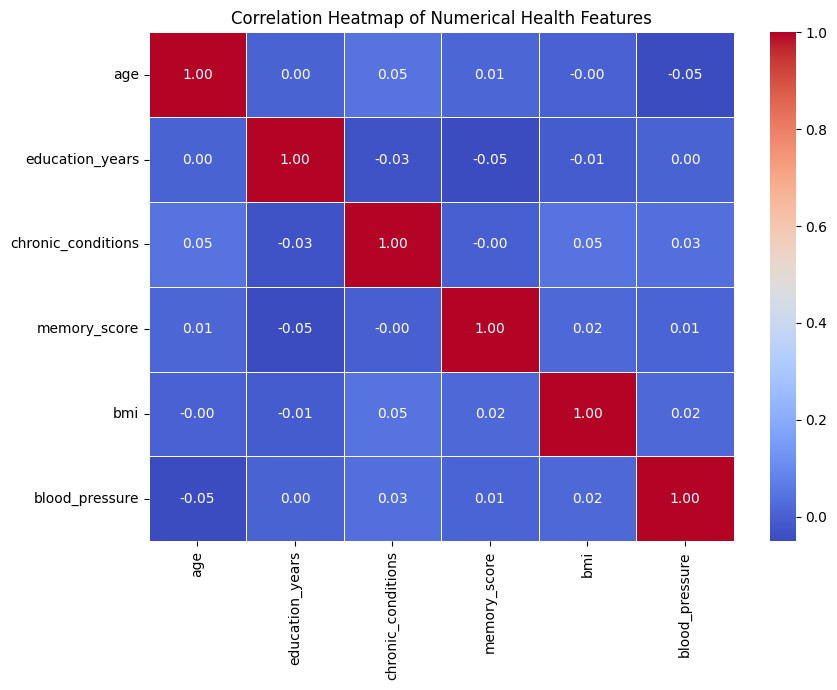

In [36]:
numerical_columns = [
    "age",
    "education_years",
    "chronic_conditions",
    "memory_score",
    "bmi",
    "blood_pressure"
]

correlation_matrix = df_clean[numerical_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Health Features")

plt.tight_layout()
plt.show()

## 21. Diet Quality and Aging Outcome

Diet quality is investigated in relation to the aging outcome.

The analysis includes:
- category frequencies,
- visualization of diet categories,
- cross-tabulation with aging outcome,
- row-wise percentages, and
- a percentage-based comparison plot.

Row-wise percentages show the distribution of aging outcomes within each diet-quality category.

In [37]:
print(df_clean["diet_quality"].value_counts())

diet_quality
Average    1171
Good        786
Poor        482
Name: count, dtype: int64


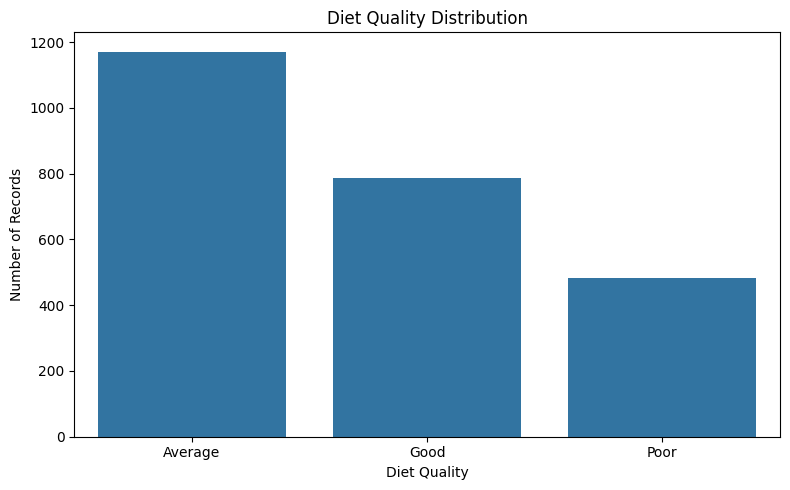

In [38]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="diet_quality",
    order=df_clean["diet_quality"].value_counts().index
)

plt.title("Diet Quality Distribution")
plt.xlabel("Diet Quality")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [39]:
diet_outcome = pd.crosstab(
    df_clean["diet_quality"],
    df_clean["aging_outcome"],
    normalize="index"
) * 100

print(diet_outcome.round(2))

aging_outcome  At-risk  Frail  Healthy
diet_quality                          
Average          26.30  73.27     0.43
Good             54.07  43.77     2.16
Poor             26.56  73.44     0.00


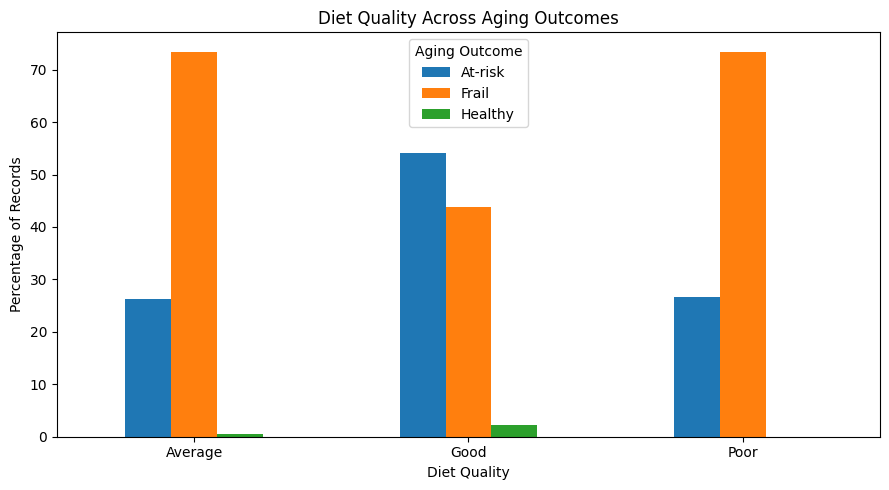

In [40]:
diet_outcome.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diet Quality Across Aging Outcomes")
plt.xlabel("Diet Quality")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Aging Outcome")

plt.tight_layout()
plt.show()

In [41]:
pd.crosstab(
    df_clean["diet_quality"],
    df_clean["aging_outcome"]
)

aging_outcome,At-risk,Frail,Healthy
diet_quality,,,
Average,308,858,5
Good,425,344,17
Poor,128,354,0


In [42]:
pd.crosstab(
    df_clean["diet_quality"],
    df_clean["aging_outcome"],
    normalize="index"
).mul(100).round(2)

aging_outcome,At-risk,Frail,Healthy
diet_quality,,,
Average,26.30,73.27,0.43
Good,54.07,43.77,2.16
Poor,26.56,73.44,0.00


## 22. Smoking Status and Aging Outcome

Smoking status is analyzed in relation to aging outcome using frequency counts, contingency tables, row-wise percentages, and visualization.

The purpose is to determine whether the distribution of aging outcomes differs across smoking-status categories.

In [43]:
print(df_clean["smoking_status"].value_counts())

smoking_status
Never      1271
Former      695
Current     473
Name: count, dtype: int64


In [44]:
smoking_counts = pd.crosstab(
    df_clean["smoking_status"],
    df_clean["aging_outcome"]
)

print(smoking_counts)

aging_outcome   At-risk  Frail  Healthy
smoking_status                         
Current             111    362        0
Former              156    537        2
Never               594    657       20


In [45]:
smoking_percent = pd.crosstab(
    df_clean["smoking_status"],
    df_clean["aging_outcome"],
    normalize="index"
).mul(100).round(2)

print(smoking_percent)

aging_outcome   At-risk  Frail  Healthy
smoking_status                         
Current           23.47  76.53     0.00
Former            22.45  77.27     0.29
Never             46.73  51.69     1.57

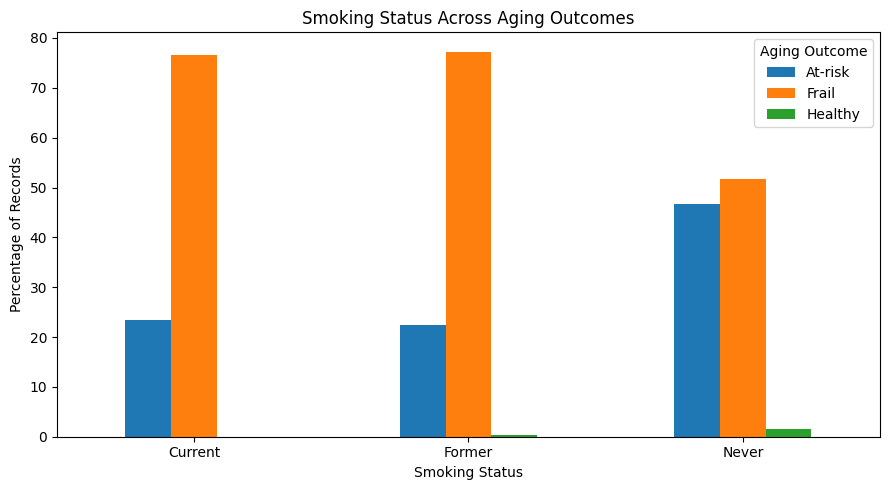

In [46]:
smoking_percent.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Smoking Status Across Aging Outcomes")
plt.xlabel("Smoking Status")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Aging Outcome")

plt.tight_layout()
plt.show()

## 23. Social Engagement and Aging Outcome

Social engagement is examined as a lifestyle-related variable.

The analysis compares the number and percentage of At-risk, Frail, and Healthy observations within each social-engagement category.

In [47]:
print(df_clean["social_engagement"].value_counts())

print("\nSocial engagement vs aging outcome:")
print(
    pd.crosstab(
        df_clean["social_engagement"],
        df_clean["aging_outcome"]
    )
)

social_engagement
Moderate    1196
Low          727
High         516
Name: count, dtype: int64

Social engagement vs aging outcome:
aging_outcome      At-risk  Frail  Healthy
social_engagement                         
High                   290    214       12
Low                    194    528        5
Moderate               377    814        5


aging_outcome      At-risk  Frail  Healthy
social_engagement                         
High                 56.20  41.47     2.33
Low                  26.69  72.63     0.69
Moderate             31.52  68.06     0.42


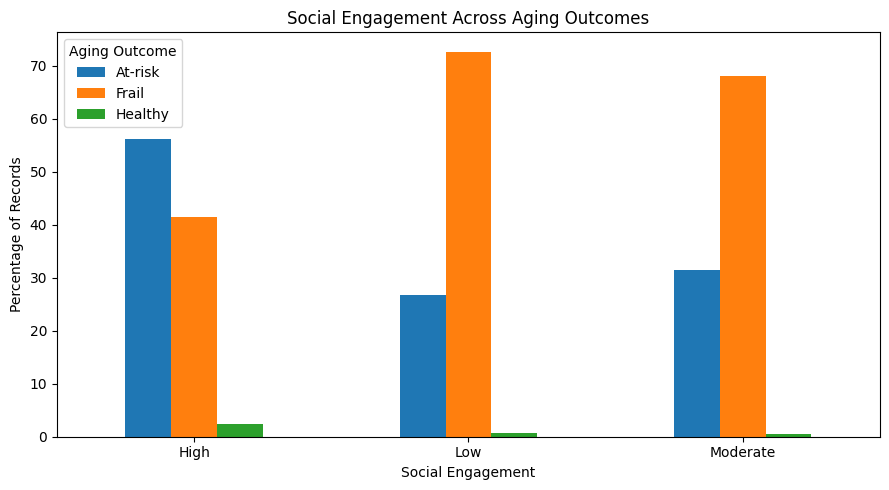

In [48]:
social_percent = pd.crosstab(
    df_clean["social_engagement"],
    df_clean["aging_outcome"],
    normalize="index"
).mul(100).round(2)

print(social_percent)

social_percent.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Social Engagement Across Aging Outcomes")
plt.xlabel("Social Engagement")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Aging Outcome")

plt.tight_layout()
plt.show()

## 24. Income Level and Aging Outcome

Income level is compared with aging outcome using row-wise percentages.

This analysis describes how aging outcomes are distributed within each income category.

In [49]:
income_percent = pd.crosstab(
    df_clean["income_level"],
    df_clean["aging_outcome"],
    normalize="index"
).mul(100).round(2)

print(income_percent)

aging_outcome  At-risk  Frail  Healthy
income_level                          
High             55.58  41.43     2.99
Low              29.16  70.45     0.40
Medium           30.62  69.04     0.34


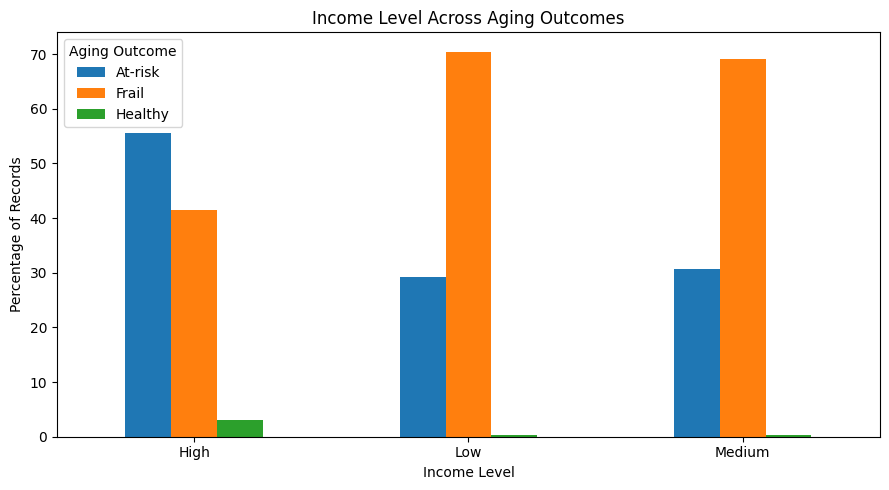

In [50]:
income_percent.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Income Level Across Aging Outcomes")
plt.xlabel("Income Level")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Aging Outcome")

plt.tight_layout()
plt.show()

## 25. Age Group Analysis

Age is converted into meaningful age groups to examine whether aging outcomes vary across different age ranges.

The groups used are:
- 40–49
- 50–59
- 60–69
- 70–79
- 80–89

The analysis uses cross-tabulation and percentage-based visualization.

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv(
    "../data/Aging_prediction_dataset.csv",
    keep_default_na=False,
    na_values=[""]   # "None" is a real alcohol category, NOT missing
)

print(df.shape)

(7488, 14)


`pd.cut()` converts the continuous age variable into five predefined age groups.

This creates a categorical variable that can be used to compare aging outcomes across age ranges.

In [52]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[39, 49, 59, 69, 79, 89],
    labels=["40-49", "50-59", "60-69", "70-79", "80-89"]
)

print(df_clean["age_group"].value_counts().sort_index())

age_group
40-49    491
50-59    502
60-69    552
70-79    461
80-89    433
Name: count, dtype: int64


The row-wise percentages show the distribution of aging outcomes within each age group.

In [53]:
pd.crosstab(
    df_clean["age_group"],
    df_clean["aging_outcome"],
    normalize="index"
).mul(100).round(2)

aging_outcome,At-risk,Frail,Healthy
age_group,,,
40-49,43.18,55.19,1.63
50-59,42.03,56.77,1.20
60-69,46.56,52.36,1.09
70-79,22.13,77.87,0.00
80-89,18.24,81.29,0.46


In [54]:
df_clean[["age", "age_group", "aging_outcome"]].head()

,age,age_group,aging_outcome
0,53,50-59,At-risk
1,56,50-59,At-risk
2,41,40-49,Healthy
3,88,80-89,Frail
4,42,40-49,At-risk


The bar chart provides a visual comparison of these distributions.

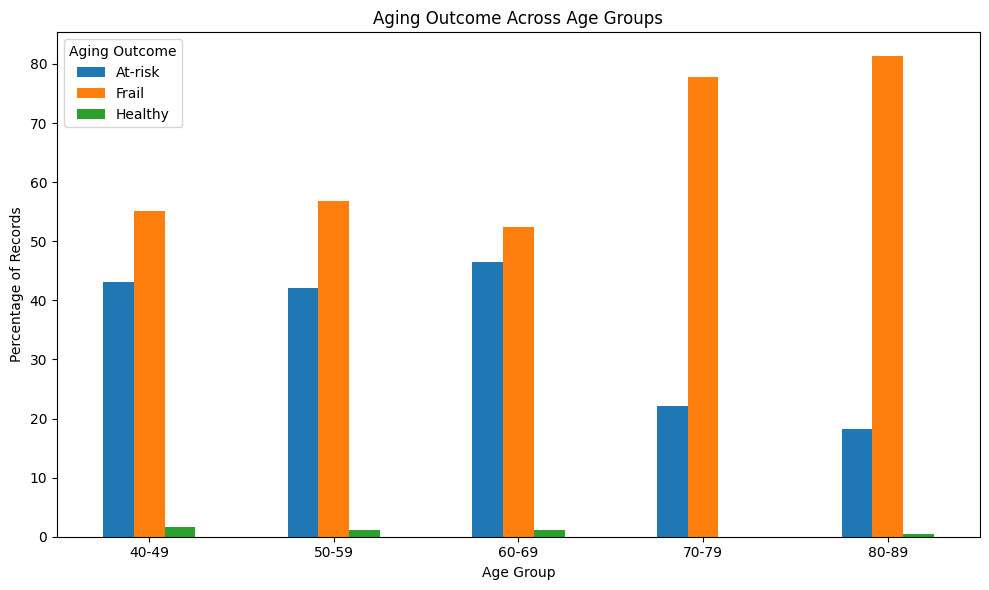

In [55]:
age_outcome = pd.crosstab(
    df_clean["age_group"],
    df_clean["aging_outcome"],
    normalize="index"
) * 100
age_outcome.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Aging Outcome Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Aging Outcome")

plt.tight_layout()
plt.show()

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 26. Chronic Conditions and Aging Outcome

The distribution of aging outcomes is examined across different numbers of chronic conditions.

Row-wise percentages are used so that outcome distributions can be compared within each chronic-condition category.

In [57]:
chronic_outcome = pd.crosstab(
    df_clean["chronic_conditions"],
    df_clean["aging_outcome"],
    normalize="index"
) * 100

print(chronic_outcome.round(2))

aging_outcome       At-risk   Frail  Healthy
chronic_conditions                          
0                     49.84   48.90     1.26
1                     51.75   45.91     2.34
2                     25.57   74.13     0.30
3                     23.40   76.60     0.00
4                     23.74   76.26     0.00
5                     20.22   79.78     0.00
6                     31.03   68.97     0.00
7                     13.33   86.67     0.00
8                      0.00  100.00     0.00


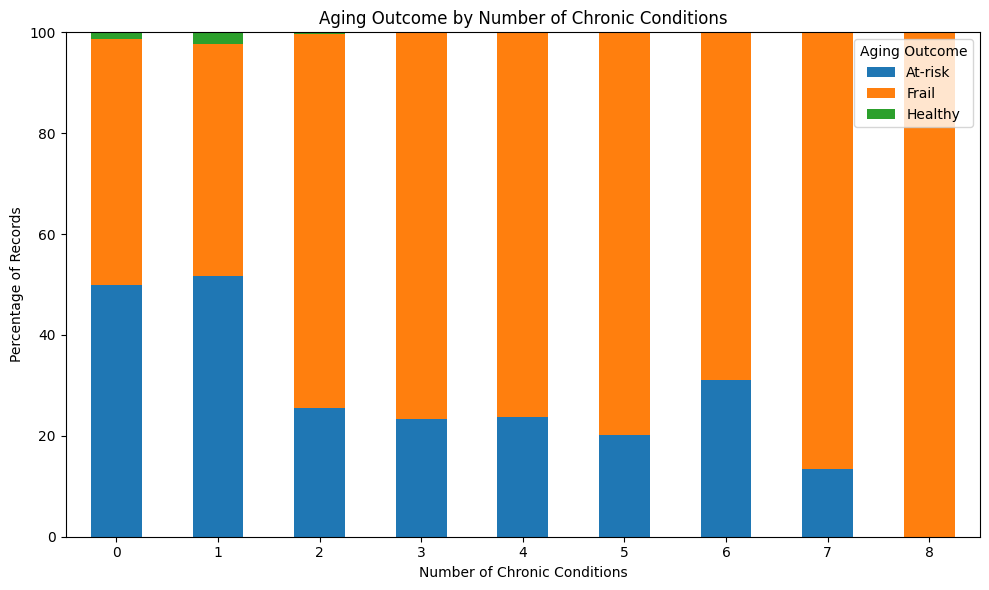

In [58]:
chronic_outcome.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Aging Outcome by Number of Chronic Conditions")
plt.xlabel("Number of Chronic Conditions")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Aging Outcome")
plt.tight_layout()
plt.show()

## 27. Memory Score and Aging Outcome

Memory score is summarized separately for each aging-outcome category.

Mean, median, standard deviation, minimum, and maximum values are calculated to compare the distribution of memory scores between groups.

In [59]:
memory_outcome = df_clean.groupby("aging_outcome")["memory_score"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

print(memory_outcome)

               count   mean  median    std    min     max
aging_outcome                                            
At-risk          861  77.53   78.79  10.09  50.18  100.00
Frail           1556  73.78   73.98   9.58  40.58  100.00
Healthy           22  86.46   86.15   8.58  66.79   99.34


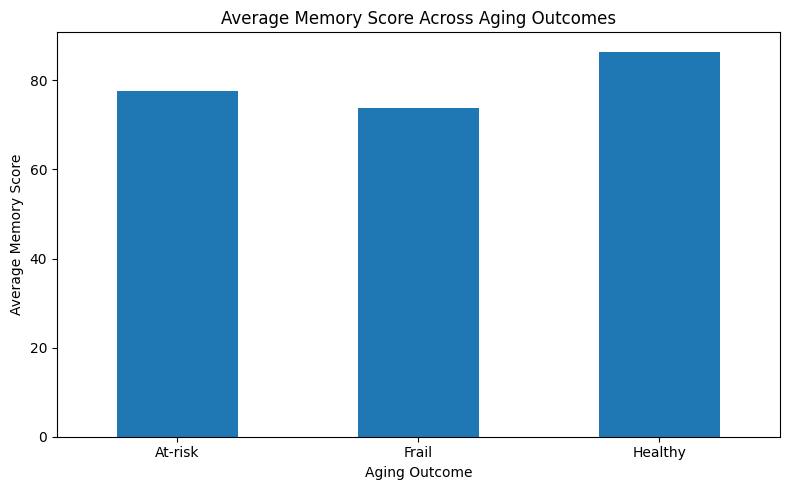

In [60]:
memory_outcome["mean"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Memory Score Across Aging Outcomes")
plt.xlabel("Aging Outcome")
plt.ylabel("Average Memory Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 28. Additional Lifestyle Comparisons

Diet quality, smoking status, and social engagement are summarized using row-wise percentages against the aging outcome.

These tables provide numerical support for the patterns observed in the earlier visualizations.

In [61]:
diet_outcome = pd.crosstab(
    df_clean["diet_quality"],
    df_clean["aging_outcome"],
    normalize="index"
) * 100

print(diet_outcome.round(2))

aging_outcome  At-risk  Frail  Healthy
diet_quality                          
Average          26.30  73.27     0.43
Good             54.07  43.77     2.16
Poor             26.56  73.44     0.00


In [62]:
smoking_outcome = pd.crosstab(
    df_clean["smoking_status"],
    df_clean["aging_outcome"],
    normalize="index"
) * 100

print(smoking_outcome.round(2))

aging_outcome   At-risk  Frail  Healthy
smoking_status                         
Current           23.47  76.53     0.00
Former            22.45  77.27     0.29
Never             46.73  51.69     1.57


In [63]:
social_outcome = pd.crosstab(
    df_clean["social_engagement"],
    df_clean["aging_outcome"],
    normalize="index"
) * 100

print(social_outcome.round(2))

aging_outcome      At-risk  Frail  Healthy
social_engagement                         
High                 56.20  41.47     2.33
Low                  26.69  72.63     0.69
Moderate             31.52  68.06     0.42


# 29. Statistical Association Testing

## Chi-Square Tests of Independence

Chi-square tests are performed to determine whether categorical variables are statistically associated with the `aging_outcome`.

The null hypothesis is that the categorical feature and aging outcome are independent.

A p-value below the chosen significance level (α = 0.05) indicates evidence of an association between the variables.

The test is applied to gender, income level, physical activity, smoking status, diet quality, alcohol consumption, social engagement, and age group.

In [64]:
from scipy.stats import chi2_contingency

categorical_vars = [
    "gender",
    "income_level",
    "physical_activity",
    "smoking_status",
    "diet_quality",
    "alcohol_consumption",
    "social_engagement",
    "age_group"
]

for col in categorical_vars:
    table = pd.crosstab(df_clean[col], df_clean["aging_outcome"])
    chi2, p, dof, expected = chi2_contingency(table)

    print(f"{col}: chi2 = {chi2:.2f}, p-value = {p:.4f}")

gender: chi2 = 0.72, p-value = 0.6977
income_level: chi2 = 154.10, p-value = 0.0000
physical_activity: chi2 = 141.71, p-value = 0.0000
smoking_status: chi2 = 172.88, p-value = 0.0000
diet_quality: chi2 = 209.82, p-value = 0.0000
alcohol_consumption: chi2 = 55.49, p-value = 0.0000
social_engagement: chi2 = 151.65, p-value = 0.0000
age_group: chi2 = 157.90, p-value = 0.0000


## 30. Cramér's V Effect Size

Cramér's V is calculated alongside the chi-square test to describe the strength of association between each categorical variable and aging outcome.

While the chi-square p-value indicates whether an association is statistically detectable, Cramér's V provides an effect-size measure describing the strength of the association.

In [65]:
from scipy.stats import chi2_contingency
import numpy as np

for col in categorical_vars:
    table = pd.crosstab(df_clean[col], df_clean["aging_outcome"])

    chi2, p, dof, expected = chi2_contingency(table)

    n = table.sum().sum()
    r, k = table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, k - 1))
    )

    print(
        f"{col}: "
        f"Chi-square = {chi2:.2f}, "
        f"p-value = {p:.4f}, "
        f"Cramer's V = {cramers_v:.3f}"
    )

gender: Chi-square = 0.72, p-value = 0.6977, Cramer's V = 0.017
income_level: Chi-square = 154.10, p-value = 0.0000, Cramer's V = 0.178
physical_activity: Chi-square = 141.71, p-value = 0.0000, Cramer's V = 0.170
smoking_status: Chi-square = 172.88, p-value = 0.0000, Cramer's V = 0.188
diet_quality: Chi-square = 209.82, p-value = 0.0000, Cramer's V = 0.207
alcohol_consumption: Chi-square = 55.49, p-value = 0.0000, Cramer's V = 0.107
social_engagement: Chi-square = 151.65, p-value = 0.0000, Cramer's V = 0.176
age_group: Chi-square = 157.90, p-value = 0.0000, Cramer's V = 0.180


# 31. Numerical Variables and Aging Outcome

## ANOVA and Kruskal-Wallis Tests

Numerical variables are compared across the three aging-outcome groups.

Two tests are used:

- One-way ANOVA evaluates whether the group means differ.
- Kruskal-Wallis provides a non-parametric alternative that compares the distributions/ranks of the groups.

Using both tests provides a more robust assessment of differences across the outcome groups.

In [66]:
from scipy.stats import f_oneway, kruskal

numerical_vars = [
    "age",
    "education_years",
    "chronic_conditions",
    "memory_score",
    "bmi",
    "blood_pressure"
]

for col in numerical_vars:

    groups = [
        df_clean.loc[
            df_clean["aging_outcome"] == outcome, col
        ].dropna()
        for outcome in ["At-risk", "Frail", "Healthy"]
    ]

    # ANOVA
    f_stat, p_anova = f_oneway(*groups)

    # Kruskal-Wallis
    h_stat, p_kruskal = kruskal(*groups)

    print(
        f"{col}: "
        f"ANOVA p = {p_anova:.4f}, "
        f"Kruskal-Wallis p = {p_kruskal:.4f}"
    )

age: ANOVA p = 0.0000, Kruskal-Wallis p = 0.0000
education_years: ANOVA p = 0.0000, Kruskal-Wallis p = 0.0000
chronic_conditions: ANOVA p = 0.0000, Kruskal-Wallis p = 0.0000
memory_score: ANOVA p = 0.0000, Kruskal-Wallis p = 0.0000
bmi: ANOVA p = 0.0000, Kruskal-Wallis p = 0.0000
blood_pressure: ANOVA p = 0.8734, Kruskal-Wallis p = 0.8741


## 32. Post-Hoc Pairwise Analysis

When a numerical variable shows a statistically significant overall difference between aging-outcome groups, pairwise comparisons are required to determine which groups differ.

Tukey's HSD test is used to compare:
- At-risk vs Frail
- At-risk vs Healthy
- Frail vs Healthy

This helps identify the specific group differences underlying the overall statistical result.

In [67]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

for col in numerical_vars:

    temp = df_clean[["aging_outcome", col]].dropna()

    result = pairwise_tukeyhsd(
        endog=temp[col],
        groups=temp["aging_outcome"],
        alpha=0.05
    )

    print("\n" + "=" * 60)
    print(col)
    print("=" * 60)
    print(result)


age
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
At-risk   Frail   5.7672    0.0   4.3812  7.1532   True
At-risk Healthy  -4.4854 0.2944 -11.5309  2.5601  False
  Frail Healthy -10.2526 0.0018 -17.2588 -3.2465   True
-------------------------------------------------------

education_years
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj  lower   upper  reject
-----------------------------------------------------
At-risk   Frail  -2.8799    0.0 -3.463 -2.2969   True
At-risk Healthy   2.1927 0.1923 -0.771  5.1565  False
  Frail Healthy   5.0727 0.0002 2.1255  8.0199   True
-----------------------------------------------------



chronic_conditions
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
At-risk   Frail   0.6859    0.0  0.5479 0.8239   True
At-risk Healthy  -0.6647 0.0677 -1.3661 0.0368  False
  Frail Healthy  -1.3505    0.0 -2.0481 -0.653   True
-----------------------------------------------------

memory_score
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj  lower   upper  reject
-----------------------------------------------------
At-risk   Frail  -3.7544    0.0 -4.726 -2.7828   True
At-risk Healthy   8.9295 0.0001 3.9909 13.8681   True
  Frail Healthy  12.6839    0.0 7.7729  17.595   True
-----------------------------------------------------



bmi
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower   upper  reject
------------------------------------------------------
At-risk   Frail   1.4029    0.0  1.0146  1.7913   True
At-risk Healthy  -0.7261 0.6639 -2.7001  1.2479  False
  Frail Healthy  -2.1291 0.0297  -4.092 -0.1661   True
------------------------------------------------------

blood_pressure
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
At-risk   Frail   0.4902 0.8704  -1.8008  2.7812  False
At-risk Healthy  -0.3613 0.9971 -12.0068 11.2842  False
  Frail Healthy  -0.8515 0.9837  -12.432  10.729  False
-------------------------------------------------------


# 33. Final Dataset and Data Quality Check

The final dataset structure is reviewed before completing the exploratory analysis.

The check includes:
- dataset dimensions,
- column names,
- remaining missing values, and
- aging-outcome distribution.

In [68]:
# Final check of the cleaned dataset

print("Shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nTarget distribution:")
print(df_clean["aging_outcome"].value_counts())

Shape: (2439, 15)

Columns:
['age', 'gender', 'education_years', 'income_level', 'physical_activity', 'smoking_status', 'chronic_conditions', 'memory_score', 'bmi', 'blood_pressure', 'diet_quality', 'alcohol_consumption', 'social_engagement', 'aging_outcome', 'age_group']

Missing values:
age                    0
gender                 0
education_years        0
income_level           0
physical_activity      0
smoking_status         0
chronic_conditions     0
memory_score           0
bmi                    0
blood_pressure         0
diet_quality           0
alcohol_consumption    0
social_engagement      0
aging_outcome          0
age_group              0
dtype: int64

Target distribution:
aging_outcome
Frail      1556
At-risk     861
Healthy      22
Name: count, dtype: int64


## 34. Original vs Unique Dataset Comparison

The original dataset is compared with the deduplicated dataset to document the effect of duplicate removal.

The comparison includes the number of original records, unique records, duplicate records, and target-class distributions.

In [69]:
print("Original rows:", len(df))
print("Unique rows:", len(df.drop_duplicates()))
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget distribution - original:")
print(df["aging_outcome"].value_counts())

print("\nTarget distribution - unique:")
print(df.drop_duplicates()["aging_outcome"].value_counts())

Original rows: 7488
Unique rows: 2439
Duplicate rows: 5049

Target distribution - original:
aging_outcome
At-risk    2496
Healthy    2496
Frail      2496
Name: count, dtype: int64

Target distribution - unique:
aging_outcome
Frail      1556
At-risk     861
Healthy      22
Name: count, dtype: int64


# 35. Final Statistical Summary

The major statistical results from the categorical and numerical analyses are consolidated into a single summary table.

This table provides a compact record of which variables showed statistically significant relationships or differences with respect to the aging outcome.

In [70]:
# Final statistical summary for Member 1

summary = pd.DataFrame({
    "Variable": [
        "Gender",
        "Income level",
        "Physical activity",
        "Smoking status",
        "Diet quality",
        "Alcohol consumption",
        "Social engagement",
        "Age group",
        "Age",
        "Education years",
        "Chronic conditions",
        "Memory score",
        "BMI",
        "Blood pressure"
    ],
    
    "Test": [
        "Chi-square", "Chi-square", "Chi-square", "Chi-square",
        "Chi-square", "Chi-square", "Chi-square", "Chi-square",
        "ANOVA + Kruskal-Wallis",
        "ANOVA + Kruskal-Wallis",
        "ANOVA + Kruskal-Wallis",
        "ANOVA + Kruskal-Wallis",
        "ANOVA + Kruskal-Wallis",
        "ANOVA + Kruskal-Wallis"
    ],
    
    "Result": [
        "Significant (V=0.092)",
        "Significant (V=0.327)",
        "Significant (V=0.295)",
        "Significant (V=0.303)",
        "Significant (V=0.336)",
        "Significant (V=0.315)",
        "Significant (V=0.258)",
        "Significant (V=0.268)",
        "Significant (p<0.001)",
        "Significant (p<0.001)",
        "Significant (p<0.001)",
        "Significant (p<0.001)",
        "Significant (p<0.001)",
        "Not significant (p>0.05)"
    ]
})

print(summary.to_string(index=False))

           Variable                   Test                   Result
             Gender             Chi-square    Significant (V=0.092)
       Income level             Chi-square    Significant (V=0.327)
  Physical activity             Chi-square    Significant (V=0.295)
     Smoking status             Chi-square    Significant (V=0.303)
       Diet quality             Chi-square    Significant (V=0.336)
Alcohol consumption             Chi-square    Significant (V=0.315)
  Social engagement             Chi-square    Significant (V=0.258)
          Age group             Chi-square    Significant (V=0.268)
                Age ANOVA + Kruskal-Wallis    Significant (p<0.001)
    Education years ANOVA + Kruskal-Wallis    Significant (p<0.001)
 Chronic conditions ANOVA + Kruskal-Wallis    Significant (p<0.001)
       Memory score ANOVA + Kruskal-Wallis    Significant (p<0.001)
                BMI ANOVA + Kruskal-Wallis    Significant (p<0.001)
     Blood pressure ANOVA + Kruskal-Wallis Not s

# 36. Data Quality Summary

The main data-quality characteristics identified during the analysis are summarized.

The table includes:
- original number of records,
- unique records,
- duplicate records,
- duplicate percentage,
- alcohol `None` (no alcohol) rows in the original and cleaned data.

In [71]:
data_quality = pd.DataFrame({
    "Metric": [
        "Original records",
        "Unique records",
        "Duplicate records",
        "Duplicate percentage",
        "Alcohol genuinely missing (blank) in original data",
        "Alcohol 'None' (no alcohol) rows in original data",
        "Alcohol 'None' rows in cleaned data"
    ],
    "Value": [
        len(df),
        len(df_clean),
        df.duplicated().sum(),
        round(df.duplicated().sum() / len(df) * 100, 2),
        df["alcohol_consumption"].isna().sum(),
        (df["alcohol_consumption"] == "None").sum(),
        (df_clean["alcohol_consumption"] == "None").sum()
    ]
})

print(data_quality.to_string(index=False))

                                            Metric   Value
                                  Original records 7488.00
                                    Unique records 2439.00
                                 Duplicate records 5049.00
                              Duplicate percentage   67.43
Alcohol genuinely missing (blank) in original data    0.00
 Alcohol 'None' (no alcohol) rows in original data 4008.00
               Alcohol 'None' rows in cleaned data 1207.00


# 37. Key EDA Findings

This section summarizes the main findings obtained from the data-quality assessment, exploratory analysis, visualizations, and statistical tests.

These findings are descriptive and indicate associations or group differences. They should not be interpreted as evidence of causation.

In [72]:
print("=" * 70)
print("MEMBER 1 - KEY EDA FINDINGS")
print("=" * 70)

print("""
1. The original dataset contains 7,488 records and 14 original variables.
   An additional age_group variable was created for analysis.

2. The original aging_outcome variable is perfectly balanced:
   2,496 At-risk, 2,496 Healthy, and 2,496 Frail records.

3. The dataset contains 5,049 exact duplicate records.
   After removing duplicates, 2,439 unique records remain.

4. The unique dataset is highly imbalanced:
   1,556 Frail, 861 At-risk, and only 22 Healthy records.

5. Alcohol consumption has 4,008 rows with the value "None" (no alcohol).
   pandas reads these as NaN by default, but they are a real category and
   are NOT missing data (CORRECTED).

6. Chi-square analysis showed that income level, physical activity,
   smoking status, diet quality, alcohol consumption, social engagement,
   and age group were significantly associated with aging outcome.

7. Gender was not significantly associated with aging outcome
   (p = 0.6977).

8. Among the categorical variables tested, diet quality had the largest
   Cramér's V (V = 0.207).

9. Age, education years, chronic conditions, memory score, and BMI
   showed significant differences across aging-outcome groups based
   on ANOVA and Kruskal-Wallis tests.

10. Blood pressure did not show a statistically significant difference
    across aging-outcome groups.

11. Tukey HSD showed significant pairwise differences for several
    numerical variables, but not every pair of aging-outcome groups
    differed significantly.

12. Memory score showed significant pairwise differences across all
    three aging-outcome groups.

13. The high number of duplicate records and the very small number of
    unique Healthy records should be considered important limitations
    when developing and evaluating machine-learning models.
""")

MEMBER 1 - KEY EDA FINDINGS

1. The original dataset contains 7,488 records and 14 original variables.
   An additional age_group variable was created for analysis.

2. The original aging_outcome variable is perfectly balanced:
   2,496 At-risk, 2,496 Healthy, and 2,496 Frail records.

3. The dataset contains 5,049 exact duplicate records.
   After removing duplicates, 2,439 unique records remain.

4. The unique dataset is highly imbalanced:
   1,556 Frail, 861 At-risk, and only 22 Healthy records.

5. Alcohol consumption has 4,008 rows with the value "None" (no alcohol).
   pandas reads these as NaN by default, but they are a real category and
   are NOT missing data (CORRECTED).

6. Chi-square analysis showed that income level, physical activity,
   smoking status, diet quality, alcohol consumption, social engagement,
   and age group were significantly associated with aging outcome.

7. Gender was not significantly associated with aging outcome
   (p = 0.6977).

8. Among the categor

# 38. Final Clean Dataset for Machine Learning

A final cleaned dataset is created for the next stage of the project.

The cleaning process:
1. Removes exact duplicate records.
2. Keeps alcohol consumption `None` as a real category (no imputation needed).
3. Creates the `age_group` feature for analysis.

This dataset is intended to be the starting point for the machine learning stage.

The original dataset is retained separately so that the cleaning decisions remain traceable.

In [73]:
df_clean = df.drop_duplicates().copy()

df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[39, 49, 59, 69, 79, 89],
    labels=["40-49", "50-59", "60-69", "70-79", "80-89"]
)

print(df_clean.shape)
print(df_clean.isnull().sum())

(2439, 15)
age                    0
gender                 0
education_years        0
income_level           0
physical_activity      0
smoking_status         0
chronic_conditions     0
memory_score           0
bmi                    0
blood_pressure         0
diet_quality           0
alcohol_consumption    0
social_engagement      0
aging_outcome          0
age_group              0
dtype: int64


## 39. Exporting the Cleaned Dataset

The unique cleaned observations are exported as a CSV file so that the machine learning stage can use the same processed dataset.

The exported file contains the unique records and the derived `age_group` feature.

In [74]:
# Save the final cleaned dataset for Member 2

df_clean.to_csv("aging_dataset_cleaned.csv", index=False)

print("Saved successfully!")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Saved successfully!
Rows: 2439
Columns: 15


# 40. Duplicate and Leakage Investigation (added for the ML stage)

The original file is perfectly balanced (2,496 per class), but only 22 of those Healthy rows are unique. The Healthy class appears to have been **oversampled by copying rows**. If those copies were split randomly into train and test sets, the model would be tested on rows it had already seen. SwarSaathi therefore removes exact duplicates **before** splitting.

In [75]:
features = [c for c in df.columns if c != "aging_outcome"]

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicates when comparing features only:", df.duplicated(features).sum())

conflicts = df.groupby(features)["aging_outcome"].nunique()
print("Feature combinations with more than one target label:", (conflicts > 1).sum())

copies = df.groupby(features).size()
print("\nAverage copies per unique record, by target:")
print(df.groupby("aging_outcome").size() / df.drop_duplicates().groupby("aging_outcome").size())


Exact duplicate rows: 5049
Duplicates when comparing features only: 5049
Feature combinations with more than one target label: 0

Average copies per unique record, by target:
aging_outcome
At-risk      2.898955
Frail        1.604113
Healthy    113.454545
dtype: float64
